# VascX vessels: walkthrough and the paper-vs-new check

Photos come from **Orthanc**, never a path on this machine: load your data first
(`MONAI_Deploy_Express/LOCAL_SCRIPTS/upload.sh /path/to/dicom`). Then, on the same photos:

1. the new model (`vessels_may26`, what the MAP deploys) step by step, with this folder's `vessels.py`;
2. **the paper's model** (`vessels_july24`, Vargas Quiros et al., *TVST* 2025,
   [doi:10.1167/tvst.14.7.19](https://doi.org/10.1167/tvst.14.7.19)) run with the authors' own code,
   compared with the new model run with ours. If they roughly match, the new model is what the MAP uses.

Kernel **Python (vascx)** (`VascX_App/requirements.txt`). Weights: `bash VascX_App/fetch_model.sh`.
Everything needed is in this folder, so the folder can move. `compare_paper_model.py` is the scripted version.

In [1]:
import json, tempfile, urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

import vessels                                   # the new model, our code
import compare_paper_model as cpm                # the paper's model, the authors' code
from orthanc import ORTHANC_URL, fetch

PATIENT = None                                   # a PatientID in Orthanc; None = the first patient there
if PATIENT is None:
    first = json.loads(urllib.request.urlopen(f"{ORTHANC_URL}/patients?expand").read())[0]
    PATIENT = first["MainDicomTags"]["PatientID"]

with fetch(patient=PATIENT) as folder:
    photos = cpm.colour_photos(folder)           # single-field colour fundus photos only, as the MAP selects
device = vessels.default_device()
model = vessels.load_model(device=device)
print(f"patient {PATIENT}: {len(photos)} colour photo(s) from {ORTHANC_URL}; on {device}")

/persist/python_virtual_environments/bearceb/.pyenv/versions/vascx/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/persist/python_virtual_environments/bearceb/.pyenv/versions/vascx/lib/python3.12/site-packages/torch/jit/_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(
/persist/python_virtual_environments/bearceb/.pyenv/versions/vascx/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


patient 3143504: 6 colour photo(s) from http://127.0.0.1:18042; on cuda


## 1. One photo, step by step

`vessels.segment()` is three steps after decoding.

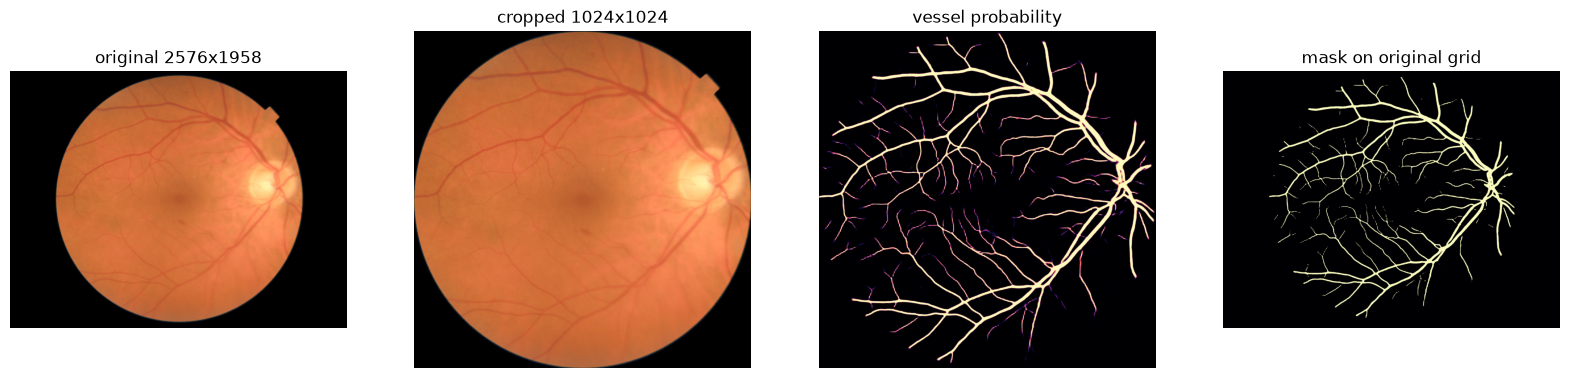

In [2]:
ds, rgb = photos[0]
cropped, transform = vessels.crop(rgb)                            # fundus circle -> 1024x1024
probability = vessels.vessel_probability(model, cropped, device)  # model + 3 flips, softmax
mask = vessels.segment(model, rgb, device)                        # back on the original grid, > 0.5

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
for a, img, title in zip(ax, [rgb, cropped, probability, mask],
                         [f"original {rgb.shape[1]}x{rgb.shape[0]}", "cropped 1024x1024", "vessel probability", "mask on original grid"]):
    a.imshow(img, cmap="magma" if img.ndim == 2 else None); a.set_title(title); a.axis("off")

## 2. Every photo

What the MAP will write as SEGs, shown as overlays.

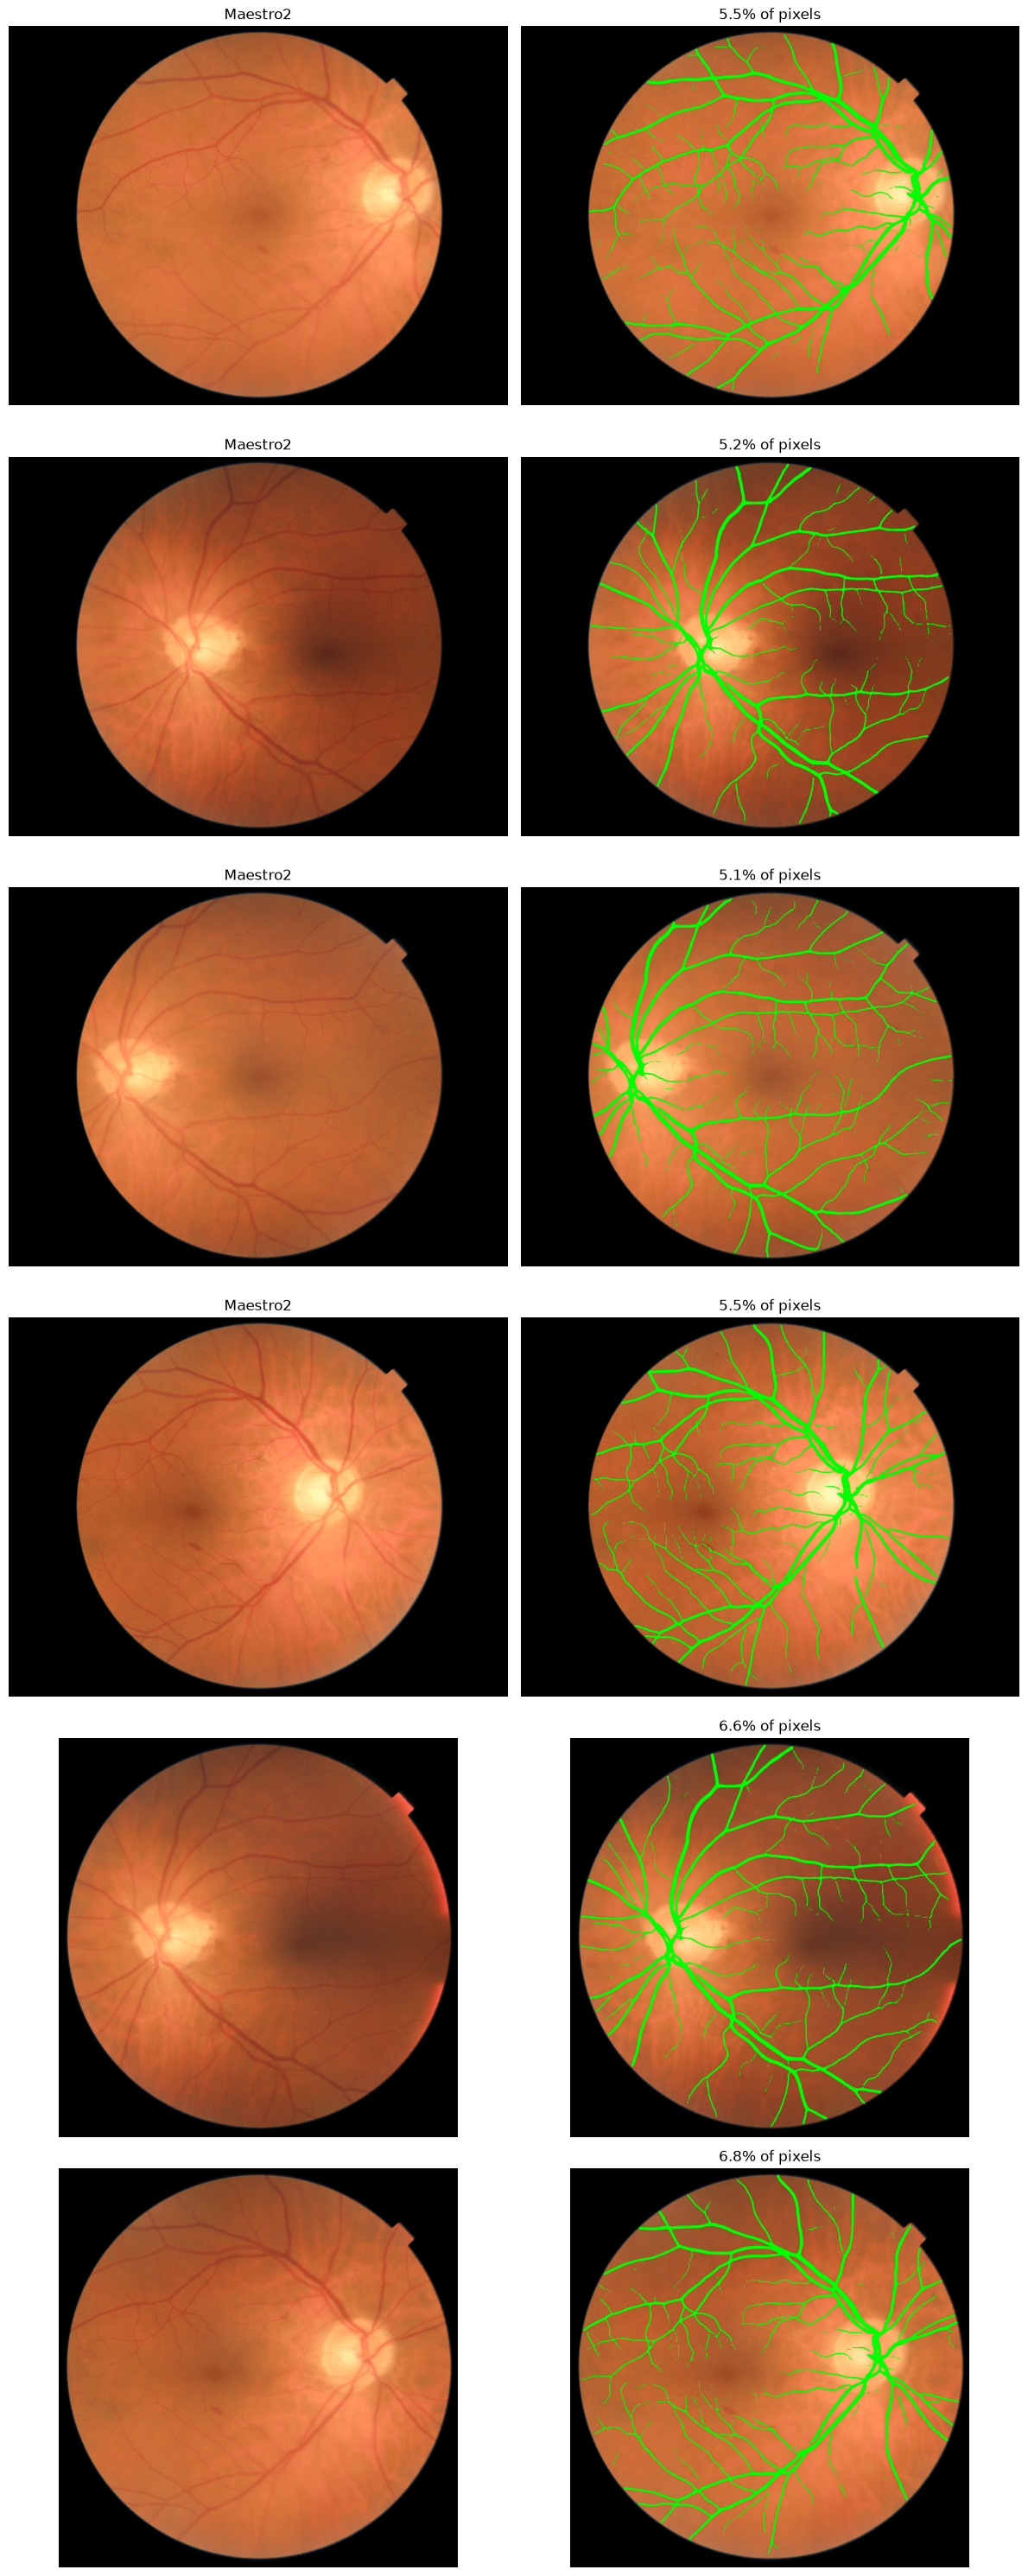

In [3]:
def overlay(rgb, mask, colour=(0, 255, 0)):
    out = rgb.copy(); out[mask > 0] = colour; return out

masks = [vessels.segment(model, rgb, device) for _, rgb in photos]
fig, axes = plt.subplots(len(photos), 2, figsize=(12, 5 * len(photos)), squeeze=False)
for (ds, rgb), m, (left, right) in zip(photos, masks, axes):
    left.imshow(rgb); left.set_title(str(ds.get("ManufacturerModelName", ""))); left.axis("off")
    right.imshow(overlay(rgb, m)); right.set_title(f"{100 * m.mean():.1f}% of pixels"); right.axis("off")
plt.tight_layout()

## 3. The paper's model vs the new model

- **Paper model**: 5-model ensemble, RGB + contrast-enhanced input, run exactly as the authors' published
  notebooks do (preprocess, then `predict_preprocessed`).
- **New model**: our `vessels.py`.
- **Check**: the new model also through the authors' code; must equal ours (~0.999, half vs full precision).

All on the same 1024x1024 crop. Two different models: expect *roughly* matching (Dice ~0.8-0.95).
Overlay colours: green both, **red paper only**, **blue new only**.

In [4]:
with tempfile.TemporaryDirectory() as workdir:
    workdir = Path(workdir)
    table = cpm.compare(photos, device, workdir)
    crops = [np.asarray(Image.open(workdir / "rgb" / f"{i}.png")) for i in range(len(photos))]
    paper = [np.asarray(Image.open(workdir / "paper" / f"{i}.png")) > 0 for i in range(len(photos))]
    new = [np.asarray(Image.open(workdir / "new" / f"{i}.png")) > 0 for i in range(len(photos))]
table.drop(columns="sop_instance_uid")

0it [00:00, ?it/s][Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
6it [00:00, 22.43it/s]
[Parallel(n_jobs=4)]: Done   2 out of   6 | elapsed:    5.5s remaining:   11.0s
[Parallel(n_jobs=4)]: Done   3 out of   6 | elapsed:    5.5s remaining:    5.5s
[Parallel(n_jobs=4)]: Done   4 out of   6 | elapsed:    5.6s remaining:    2.8s
[Parallel(n_jobs=4)]: Done   6 out of   6 | elapsed:    6.6s finished
  0%|          | 0/1 [00:00<?, ?it/s]/persist/python_virtual_environments/bearceb/.pyenv/versions/vascx/lib/python3.12/site-packages/monai/inferers/utils.py:226: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/python_variable_indexing.cpp:356.)
  win_data = tor

,image,camera,dice_paper_vs_new,vessel_pct_paper,vessel_pct_new,dice_new_authors_vs_ours
0,0,Maestro2,0.9270,8.02,7.81,0.9995
1,1,Maestro2,0.9368,7.64,7.37,0.9996
2,2,Maestro2,0.9315,7.65,7.32,0.9995
3,3,Maestro2,0.9281,8.10,7.93,0.9996
4,4,?,0.9319,7.55,7.16,0.9995
5,5,?,0.9266,7.89,7.43,0.9996


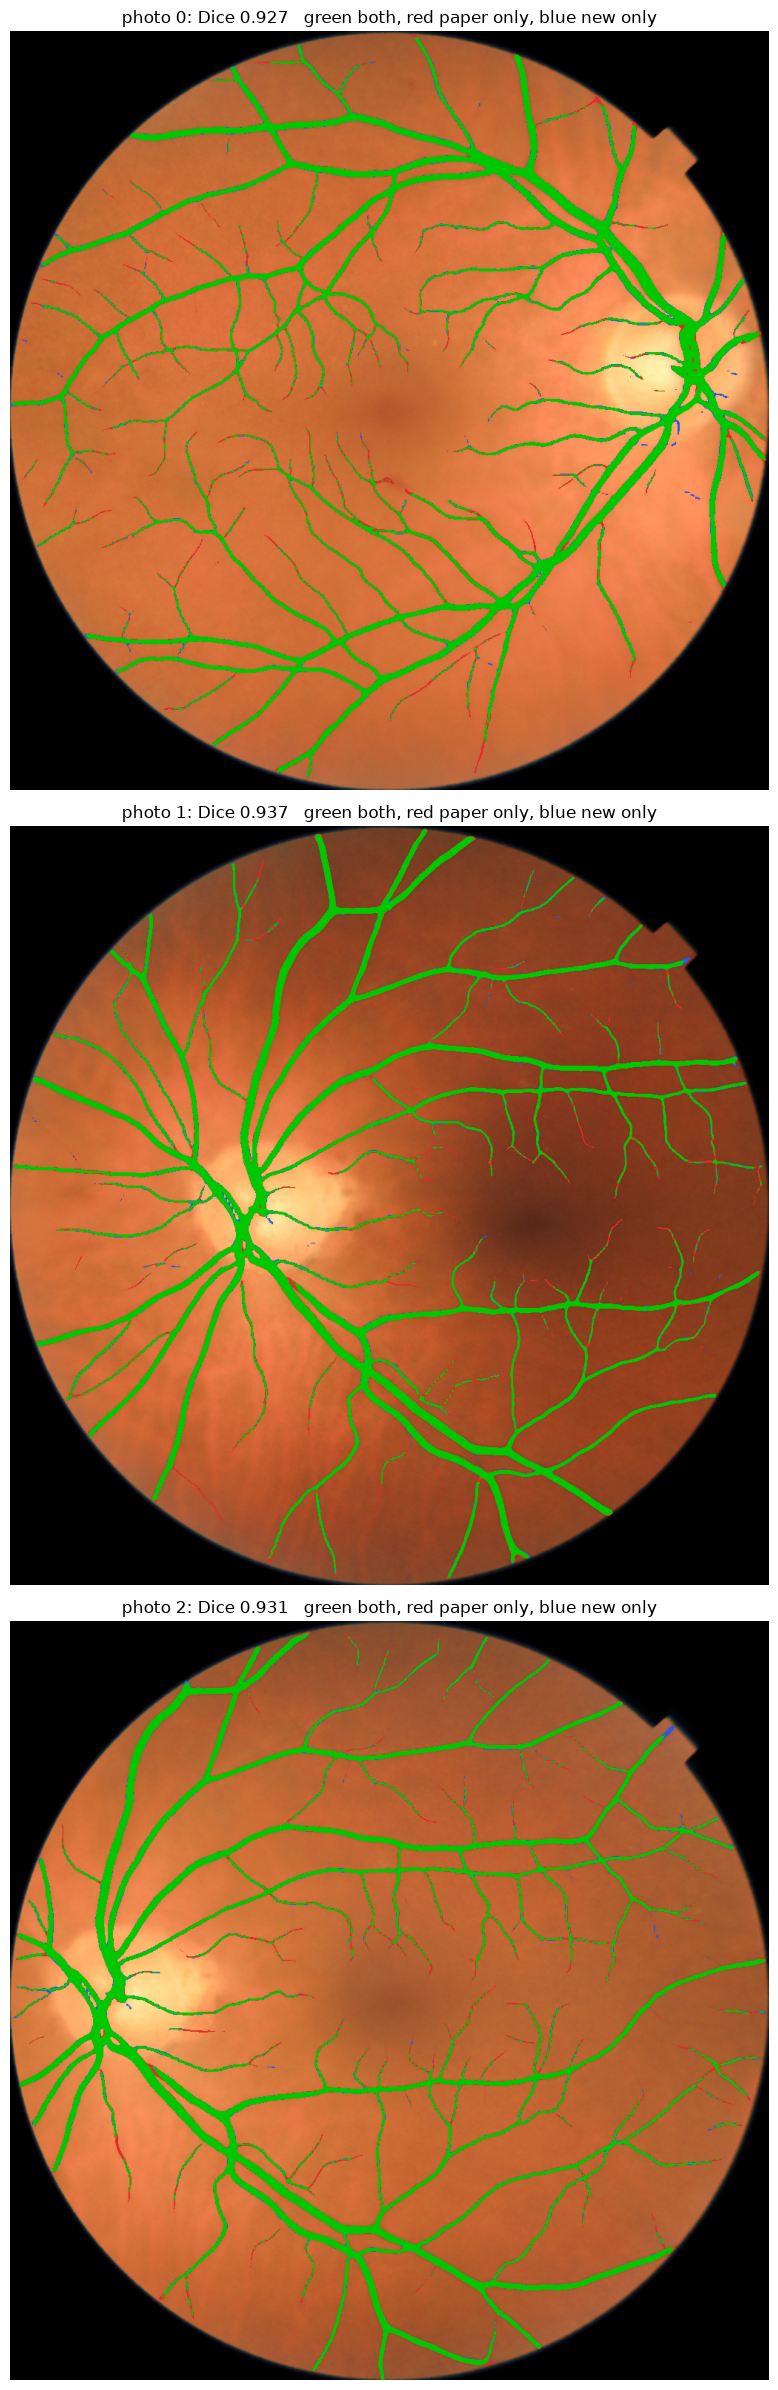

In [5]:
n = min(3, len(photos))
fig, axes = plt.subplots(n, 1, figsize=(8, 8 * n), squeeze=False)
for i, a in zip(range(n), axes[:, 0]):
    img = crops[i].copy()
    img[paper[i] & new[i]] = [0, 200, 0]; img[paper[i] & ~new[i]] = [230, 40, 40]; img[~paper[i] & new[i]] = [40, 90, 230]
    a.imshow(img); a.axis("off")
    a.set_title(f"photo {i}: Dice {table.dice_paper_vs_new[i]:.3f}   green both, red paper only, blue new only")
plt.tight_layout()

## 4. Inside the new model

The deployed model is newer than the paper's:

| | paper (`vessels_july24`) | deployed (`vessels_may26`) |
|---|---|---|
| Architecture | U-Net, 8 stages | ConvNeXt-V2-tiny encoder + UperNet decoder |
| Input | RGB + contrast-enhanced (6 channels) | RGB |
| Models | 5-model ensemble | one |
| Inference | 512 sliding window over 1024 | one 1024x1024 pass |

Original authors' diagrams: ConvNeXt V2 block and FCMAE pre-training, Woo et al., CVPR 2023,
[arXiv 2301.00808](https://arxiv.org/abs/2301.00808), Figs. 5 and 2; UperNet, Xiao et al., ECCV 2018,
[arXiv 1807.10221](https://arxiv.org/abs/1807.10221); fundus cropping, the VascX paper's Fig. 3.
Structure and training config travel inside the `.pt` file:

In [6]:
extra = {"config.yaml": ""}
torch.jit.load(str(vessels.MODEL_FILE), map_location="cpu", _extra_files=extra)
config = json.loads(extra["config.yaml"])
print("model:", {k: config["lightningmodule"][k] for k in ["class", "model_library", "architecture", "decoder", "in_channels", "n_class"]})
print("trained on:", [p.split("/")[0] for p in config["datamodule"]["dataframe_path"]])

net = model.fold0.model
for i, stage in enumerate(net.encoder.backbone.stages.children()):
    blocks = list(stage.children())
    width = next(p.shape[0] for k, p in blocks[0].named_parameters() if "dwconv.weight" in k)
    print(f"encoder stage {i}: {len(blocks)} ConvNeXt-V2 blocks, {width} channels, 1/{4 * 2 ** i} resolution")
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")

model: {'class': 'SegmentationConvnextV2LM', 'model_library': 'convnextv2', 'architecture': 'tiny', 'decoder': 'upernet', 'in_channels': 3, 'n_class': 2}
trained on: ['CHASEDB', 'DRHAGIS', 'FIVES', 'HRF', 'LEUVEN', 'RETA', 'RS']
encoder stage 0: 3 ConvNeXt-V2 blocks, 96 channels, 1/4 resolution
encoder stage 1: 3 ConvNeXt-V2 blocks, 192 channels, 1/8 resolution
encoder stage 2: 9 ConvNeXt-V2 blocks, 384 channels, 1/16 resolution
encoder stage 3: 3 ConvNeXt-V2 blocks, 768 channels, 1/32 resolution
parameters: 35.4 M


/persist/python_virtual_environments/bearceb/.pyenv/versions/vascx/lib/python3.12/site-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


```
┌───────┬────────────┬─────────────────┬──────────┬─────────────────────────────────────────────────┐
│ Stage │ Resolution │ Size of the map │ Channels │                 What it "sees"                  │
├───────┼────────────┼─────────────────┼──────────┼─────────────────────────────────────────────────┤
│ 0     │ 1/4        │ 256 × 256       │ 96       │ fine detail: edges, thin vessel segments        │
├───────┼────────────┼─────────────────┼──────────┼─────────────────────────────────────────────────┤
│ 1     │ 1/8        │ 128 × 128       │ 192      │ short vessel pieces, branches                   │
├───────┼────────────┼─────────────────┼──────────┼─────────────────────────────────────────────────┤
│ 2     │ 1/16       │ 64 × 64         │ 384      │ larger vessel patterns                          │
├───────┼────────────┼─────────────────┼──────────┼─────────────────────────────────────────────────┤
│ 3     │ 1/32       │ 32 × 32         │ 768      │ whole-image context: optic disc, overall layout │
└───────┴────────────┴─────────────────┴──────────┴─────────────────────────────────────────────────┘
```

## 5. A first metric: vessel density

Vessel pixels / fundus pixels (the fundus area from the same circle detection used for cropping).

In [7]:
from rtnls_fundusprep.mask_extraction import get_cfi_bounds

pd.DataFrame([dict(camera=str(ds.get("ManufacturerModelName", "")),
                   vessel_density=round(float((m > 0)[get_cfi_bounds(rgb).mask > 0].mean()), 4))
              for (ds, rgb), m in zip(photos, masks)])

,camera,vessel_density
0,Maestro2,0.1003
1,Maestro2,0.0945
2,Maestro2,0.0937
3,Maestro2,0.1018
4,,0.0917
5,,0.0951


## 6. From here to the MAP

If section 3 shows the new model roughly matches the paper's, the MAP uses it. Promoting a change in
`vessels.py`: copy it into `maps/fundus_vessels/model_spec.py`, bump `ALGORITHM_VERSION`, rebuild, and run the MAP's
idempotency check (`maps/fundus_vessels/README.md`). The MAP's own concern is linked, idempotent results.